# Turmeric Plant Disease Classification using a CNN

**Goal:** Design, train and analyse a Convolutional Neural Network that classifies turmeric images (leaf and rhizome) into healthy / diseased categories.

**Dataset folder structure (auto-detected):**
```
Turmeric Plant Disease/
├── Dry Leaf/
├── Healthy Leaf/
├── Leaf Blotch/
├── Rhizome Disease Root/
└── Rhizome Healthy Root/
```

**Pipeline:** Setup → EDA → Stratified split → tf.data pipeline → CNN design → Training → Evaluation & analysis → Save / Inference → (Optional) Transfer learning comparison

## 1. Setup

In [ ]:
# Uncomment and run once if packages are missing
# %pip install tensorflow scikit-learn matplotlib seaborn pandas pillow

In [1]:
import os, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: []


In [2]:
# ---------------- CONFIGURATION ----------------
# Path to the dataset folder. Relative to the notebook, or use an absolute path, e.g.
# DATA_DIR = r"C:\Users\you\Desktop\Turmeric Plant Disease"
DATA_DIR = "Turmeric Plant Disease"

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
EPOCHS     = 40
SEED       = 42
VAL_SIZE   = 0.15
TEST_SIZE  = 0.15
LR         = 1e-3

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

## 2. Load file paths and explore the data

In [3]:
data_dir = Path(DATA_DIR)
assert data_dir.exists(), f"Folder not found: {data_dir.resolve()}  -> fix DATA_DIR above"

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_names = sorted([d.name for d in data_dir.iterdir() if d.is_dir()])
class_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)

paths, labels = [], []
for c in class_names:
    for f in (data_dir / c).rglob("*"):
        if f.suffix.lower() in VALID_EXT:
            paths.append(str(f))
            labels.append(class_to_idx[c])

paths, labels = np.array(paths), np.array(labels)
print(f"Classes ({NUM_CLASSES}): {class_names}")
print(f"Total images: {len(paths)}")

Classes (5): ['Dry Leaf', 'Healthy Leaf', 'Leaf Blotch', 'Rhizome Disease Root', 'Rhizome Healthy Root']
Total images: 1063


Dry Leaf                203
Healthy Leaf            197
Leaf Blotch             199
Rhizome Disease Root    182
Rhizome Healthy Root    282
Name: count, dtype: int64


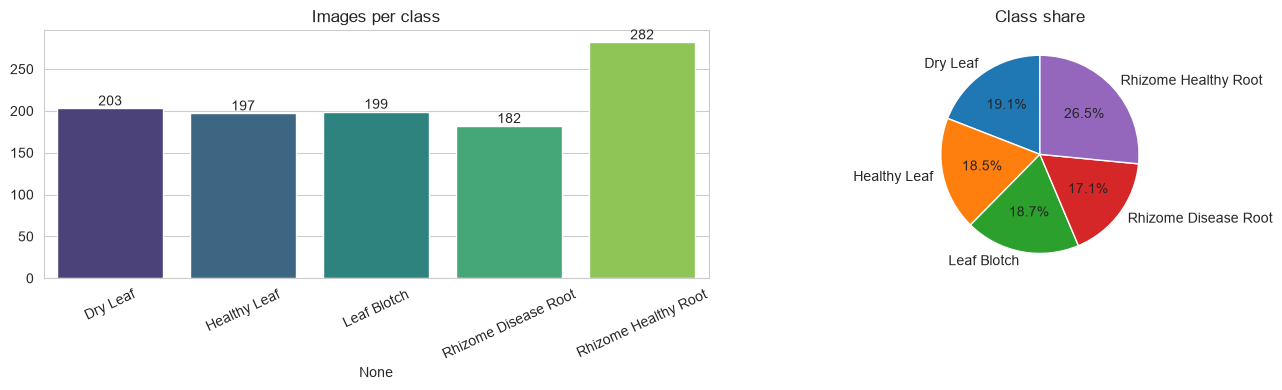

Imbalance ratio (max/min): 1.55


In [4]:
# Class distribution
counts = pd.Series(labels).map(lambda i: class_names[i]).value_counts().reindex(class_names)
print(counts)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette="viridis")
ax[0].set_title("Images per class"); ax[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(counts.values):
    ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()

imbalance = counts.max() / counts.min()
print(f"Imbalance ratio (max/min): {imbalance:.2f}")

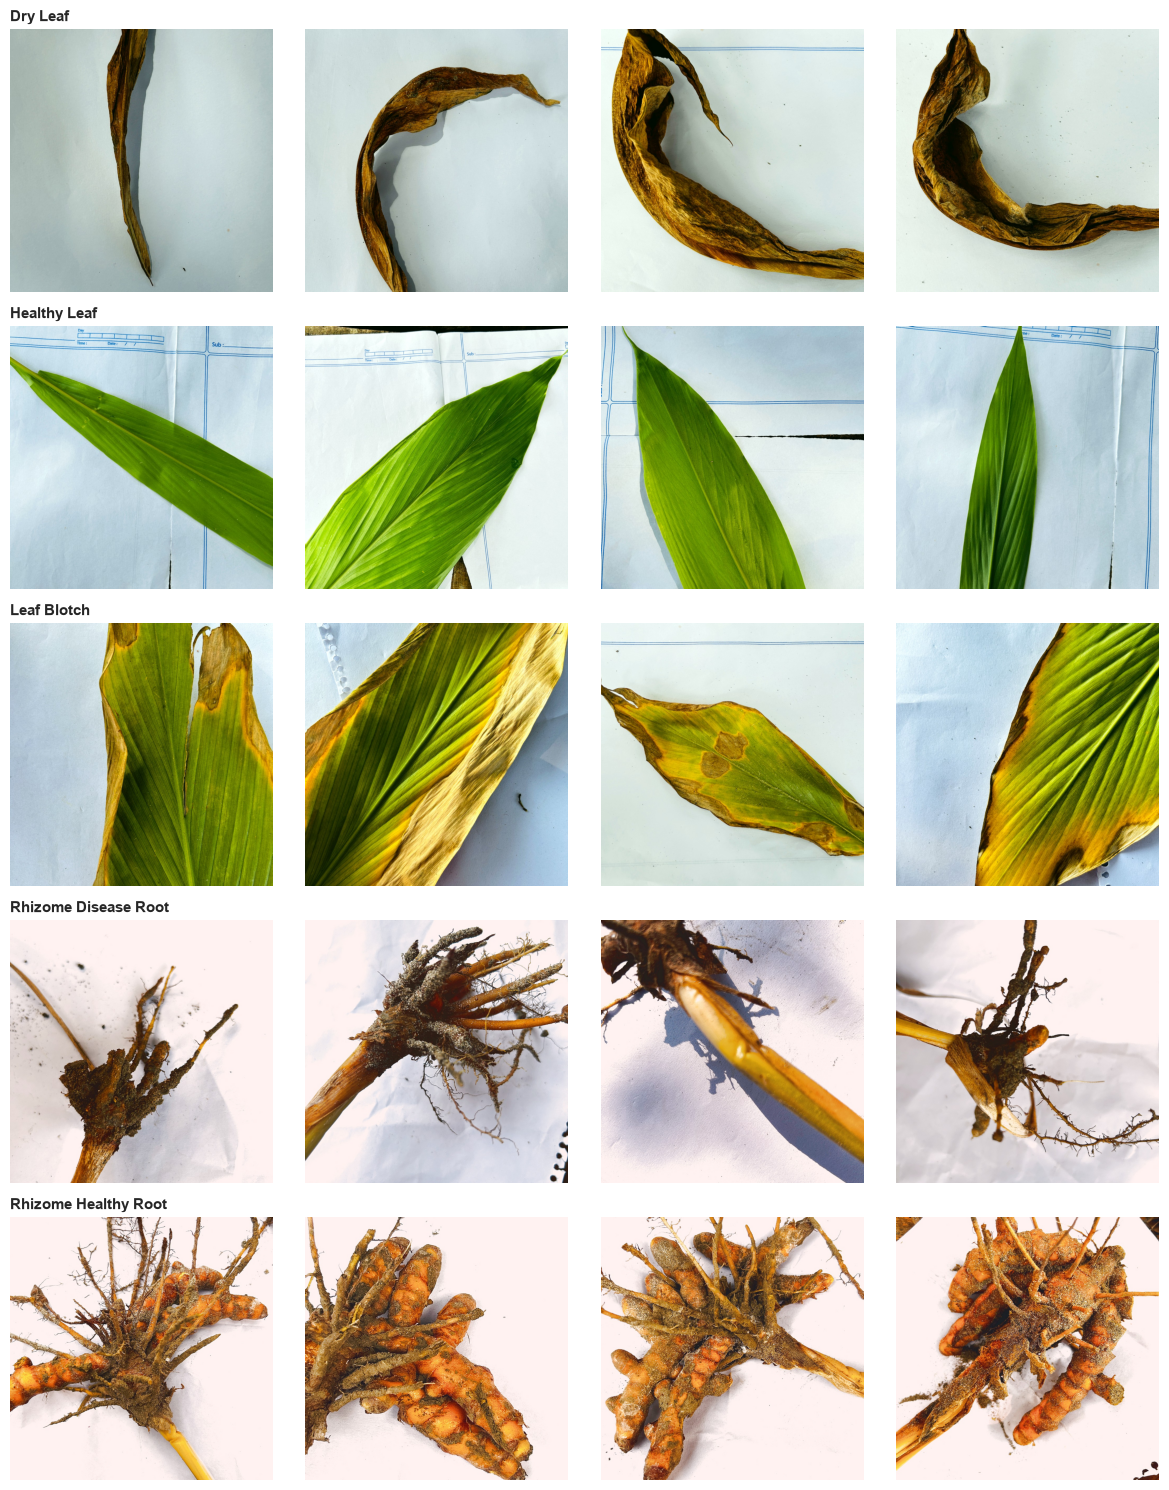

In [5]:
# Sample images from each class
n_per_class = 4
fig, axes = plt.subplots(NUM_CLASSES, n_per_class, figsize=(3 * n_per_class, 3 * NUM_CLASSES))
for r, c in enumerate(class_names):
    idxs = np.where(labels == class_to_idx[c])[0]
    for k, j in enumerate(np.random.choice(idxs, min(n_per_class, len(idxs)), replace=False)):
        axes[r, k].imshow(Image.open(paths[j]).convert("RGB"))
        axes[r, k].axis("off")
        if k == 0:
            axes[r, k].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

In [6]:
# Image size / format check on a random sample
sample = np.random.choice(paths, min(300, len(paths)), replace=False)
sizes = []
for p in sample:
    with Image.open(p) as im:
        sizes.append(im.size)
sizes = pd.DataFrame(sizes, columns=["width", "height"])
print(sizes.describe().loc[["min", "mean", "max"]].round(0))

       width  height
min   1000.0  1000.0
mean  1000.0  1000.0
max   1000.0  1000.0


## 3. Stratified Train / Validation / Test split
Stratification keeps the class proportions identical in all three sets.

In [7]:
train_p, temp_p, train_y, temp_y = train_test_split(
    paths, labels, test_size=VAL_SIZE + TEST_SIZE, stratify=labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(
    temp_p, temp_y, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE), stratify=temp_y, random_state=SEED)

print(f"Train: {len(train_p)} | Val: {len(val_p)} | Test: {len(test_p)}")

Train: 744 | Val: 159 | Test: 160


## 4. Input pipeline (`tf.data`)

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape((*IMG_SIZE, 3))
    return tf.cast(img, tf.float32), label

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_p, train_y, training=True)
val_ds   = make_ds(val_p, val_y)
test_ds  = make_ds(test_p, test_y)

# Class weights to handle any imbalance
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_y)
class_weights = {i: w for i, w in enumerate(cw)}
print("Class weights:", {class_names[i]: round(w, 2) for i, w in class_weights.items()})

Class weights: {'Dry Leaf': np.float64(1.05), 'Healthy Leaf': np.float64(1.08), 'Leaf Blotch': np.float64(1.07), 'Rhizome Disease Root': np.float64(1.16), 'Rhizome Healthy Root': np.float64(0.76)}


## 5. CNN architecture

Design choices:
- **Data augmentation** (flip, rotation, zoom, contrast) as layers inside the model, active only during training.
- **4 convolutional blocks** (32 → 64 → 128 → 256 filters), each with `Conv → BatchNorm → ReLU → Conv → BatchNorm → ReLU → MaxPool`.
- **Global Average Pooling** instead of Flatten to reduce parameters and overfitting.
- **Dropout** + dense layer, then **softmax** output.

In [9]:
def conv_block(x, filters, drop=0.0):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)
    if drop:
        x = layers.Dropout(drop)(x)
    return x

def build_cnn(input_shape=(*IMG_SIZE, 3), num_classes=NUM_CLASSES):
    inputs = keras.Input(shape=input_shape)

    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.RandomRotation(0.15)(x)
    x = layers.RandomZoom(0.15)(x)
    x = layers.RandomContrast(0.15)(x)
    x = layers.Rescaling(1.0 / 255)(x)

    x = conv_block(x, 32)
    x = conv_block(x, 64, 0.1)
    x = conv_block(x, 128, 0.2)
    x = conv_block(x, 256, 0.3)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="turmeric_cnn")

model = build_cnn()
model.compile(
    optimizer=keras.optimizers.Adam(LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "turmeric_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,72

 Total params: 1,242,213 (4.74 MB)

 Trainable params: 1,240,293 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 6. Training

In [10]:
os.makedirs("outputs", exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint("outputs/best_turmeric_cnn.keras", monitor="val_accuracy",
                                    save_best_only=True, verbose=0),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
)

Epoch 1/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 166s 7s/step - accuracy: 0.7917 - loss: 0.5659 - val_accuracy: 0.1887 - val_loss: 1.8909 - learning_rate: 0.0010
Epoch 2/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 160s 7s/step - accuracy: 0.9126 - loss: 0.2438 - val_accuracy: 0.1698 - val_loss: 5.0536 - learning_rate: 0.0010
Epoch 3/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 166s 7s/step - accuracy: 0.9113 - loss: 0.2344 - val_accuracy: 0.1698 - val_loss: 11.8027 - learning_rate: 0.0010
Epoch 4/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9570 - loss: 0.1546
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
24/24 ━━━━━━━━━━━━━━━━━━━━ 160s 7s/step - accuracy: 0.9570 - loss: 0.1546 - val_accuracy: 0.1887 - val_loss: 5.8278 - learning_rate: 0.0010
Epoch 5/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 162s 7s/step - accuracy: 0.9704 - loss: 0.1227 - val_accuracy: 0.1887 - val_loss: 4.4845 - learning_rate: 5.0000e-04
Epoch 6/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 158s 7s/step - accuracy: 0.9718 - loss: 0.0987 - val_a

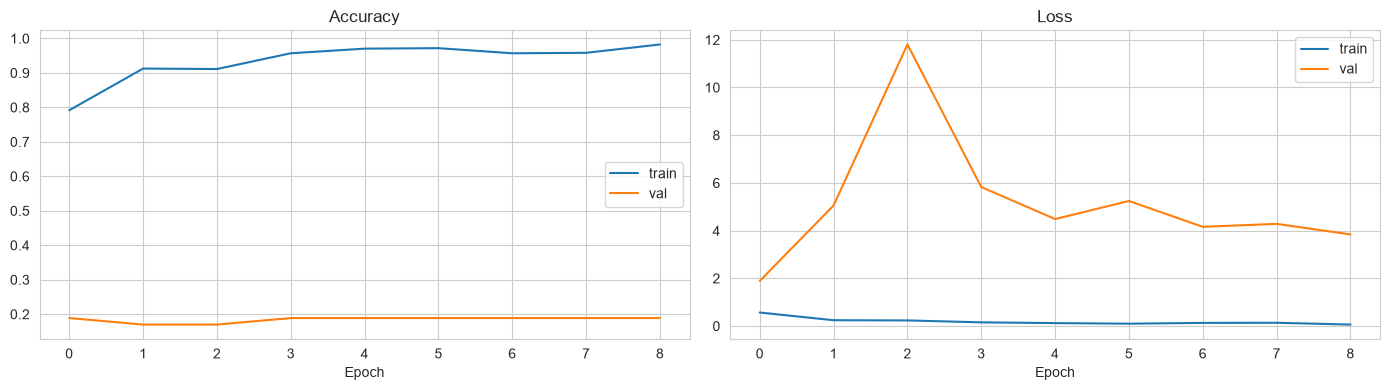

Best epoch: 1 | val_acc = 0.1887 | train_acc at that epoch = 0.7917


In [11]:
# Training curves
hist = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(hist["accuracy"], label="train"); ax[0].plot(hist["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist["loss"], label="train"); ax[1].plot(hist["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

best = hist["val_accuracy"].idxmax()
print(f"Best epoch: {best + 1} | val_acc = {hist['val_accuracy'].max():.4f} "
      f"| train_acc at that epoch = {hist['accuracy'][best]:.4f}")

## 7. Evaluation on the held-out test set

In [12]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

probs = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
y_true = test_y   # test_ds is not shuffled, so order matches test_p

print("\nClassification report:\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Test loss: 1.9504 | Test accuracy: 0.1813

Classification report:

                      precision    recall  f1-score   support

            Dry Leaf     0.0000    0.0000    0.0000        31
        Healthy Leaf     0.1859    1.0000    0.3135        29
         Leaf Blotch     0.0000    0.0000    0.0000        30
Rhizome Disease Root     0.0000    0.0000    0.0000        27
Rhizome Healthy Root     0.0000    0.0000    0.0000        43

            accuracy                         0.1812       160
           macro avg     0.0372    0.2000    0.0627       160
        weighted avg     0.0337    0.1812    0.0568       160



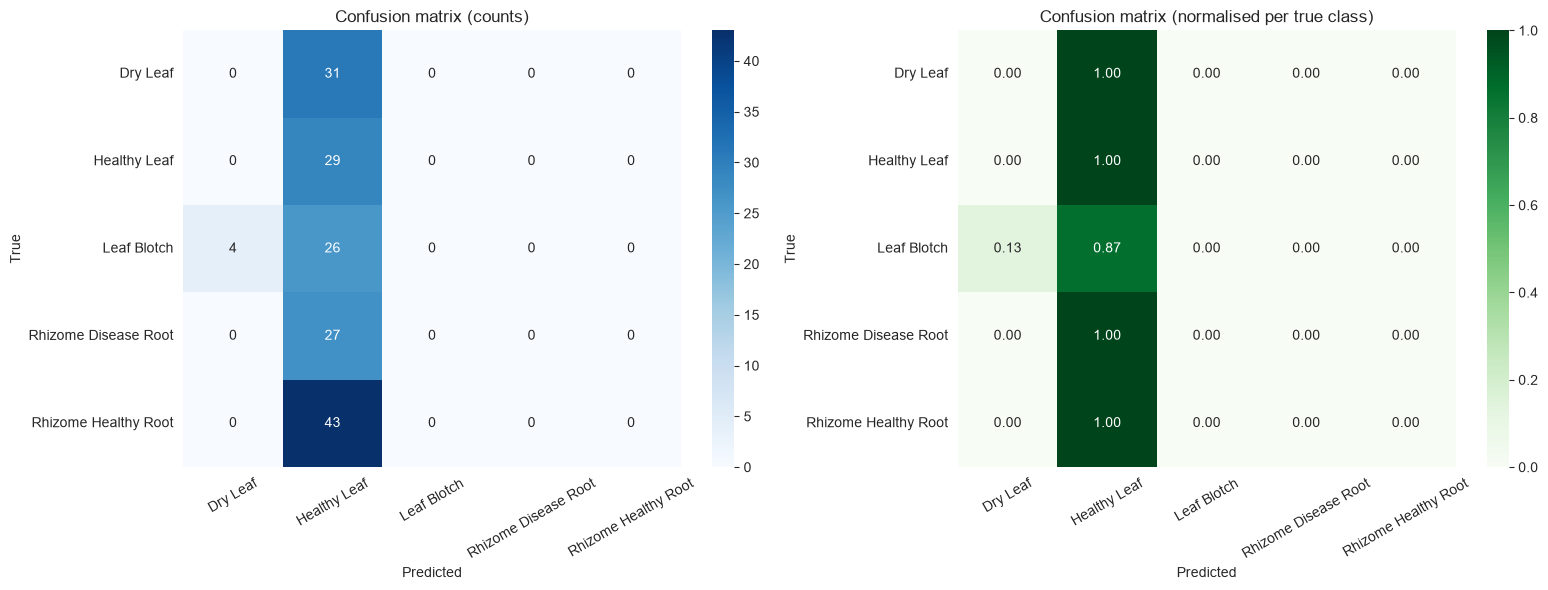

In [13]:
# Confusion matrices (counts and row-normalised)
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title("Confusion matrix (normalised per true class)")
for a in ax:
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 8. Error analysis

In [14]:
# Per-class accuracy and most common confusions
per_class = pd.DataFrame({
    "class": class_names,
    "support": cm.sum(axis=1),
    "accuracy": np.diag(cm) / cm.sum(axis=1),
}).sort_values("accuracy")
display(per_class.round(3))

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = [(class_names[i], class_names[j], cm_off[i, j])
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0]
pairs = sorted(pairs, key=lambda t: -t[2])[:5]
print("\nTop confusions (true -> predicted):")
for t, p, n in pairs:
    print(f"  {t}  ->  {p}: {n}")

,class,support,accuracy
0,Dry Leaf,31,0.0
2,Leaf Blotch,30,0.0
3,Rhizome Disease Root,27,0.0
4,Rhizome Healthy Root,43,0.0
1,Healthy Leaf,29,1.0



Top confusions (true -> predicted):
  Rhizome Healthy Root  ->  Healthy Leaf: 43
  Dry Leaf  ->  Healthy Leaf: 31
  Rhizome Disease Root  ->  Healthy Leaf: 27
  Leaf Blotch  ->  Healthy Leaf: 26
  Leaf Blotch  ->  Dry Leaf: 4


Misclassified: 131 / 160


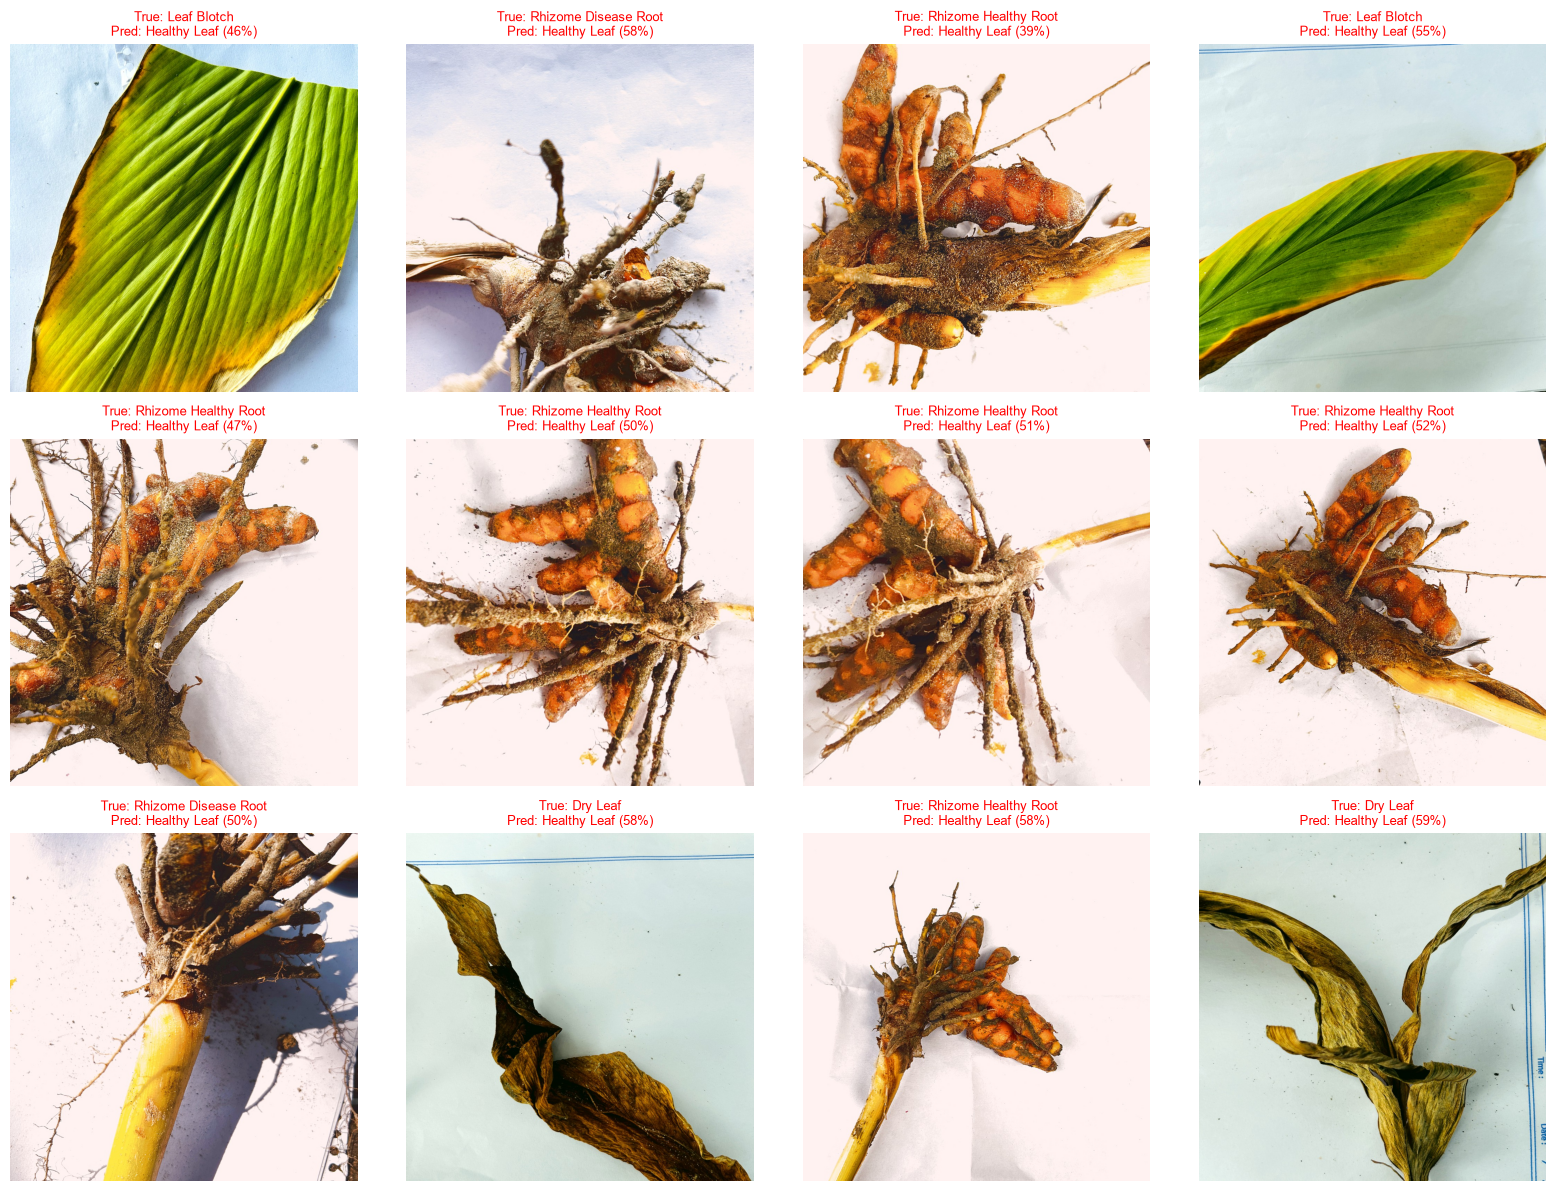

In [15]:
# Visualise misclassified images
wrong = np.where(y_pred != y_true)[0]
print(f"Misclassified: {len(wrong)} / {len(y_true)}")

show = wrong[:12]
if len(show):
    cols = 4; rows = int(np.ceil(len(show) / cols))
    plt.figure(figsize=(4 * cols, 4 * rows))
    for k, i in enumerate(show):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(Image.open(test_p[i]).convert("RGB")); plt.axis("off")
        plt.title(f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({probs[i].max():.0%})",
                  fontsize=9, color="red")
    plt.tight_layout(); plt.show()

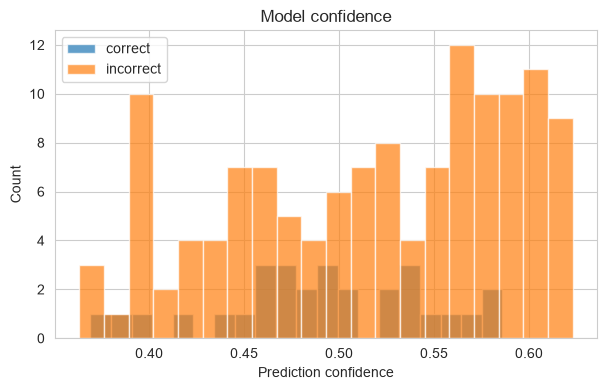

In [16]:
# Confidence distribution: correct vs incorrect predictions
conf = probs.max(axis=1)
plt.figure(figsize=(7, 4))
plt.hist(conf[y_pred == y_true], bins=20, alpha=0.7, label="correct")
if len(wrong):
    plt.hist(conf[wrong], bins=20, alpha=0.7, label="incorrect")
plt.xlabel("Prediction confidence"); plt.ylabel("Count"); plt.legend(); plt.title("Model confidence")
plt.show()

## 9. Save the model and predict on a new image

In [ ]:
model.save("outputs/turmeric_cnn_final.keras")
with open("outputs/class_names.txt", "w") as f:
    f.write("\n".join(class_names))
print("Saved to ./outputs")

In [ ]:
def predict_image(img_path, model=model, top_k=3):
    img = tf.io.decode_image(tf.io.read_file(img_path), channels=3, expand_animations=False)
    img = tf.cast(tf.image.resize(img, IMG_SIZE), tf.float32)
    p = model.predict(tf.expand_dims(img, 0), verbose=0)[0]
    order = p.argsort()[::-1][:top_k]
    plt.imshow(Image.open(img_path).convert("RGB")); plt.axis("off")
    plt.title(f"{class_names[order[0]]} ({p[order[0]]:.1%})")
    plt.show()
    for i in order:
        print(f"{class_names[i]:<25} {p[i]:.2%}")

# Example: predict a random test image
predict_image(test_p[0])

## 10. (Optional) Transfer-learning comparison with MobileNetV2
A pretrained backbone often reaches higher accuracy with less data. This section compares it against the custom CNN.
Set `RUN_TRANSFER = True` to run it.

In [ ]:
RUN_TRANSFER = False

if RUN_TRANSFER:
    base = keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False

    inp = keras.Input(shape=(*IMG_SIZE, 3))
    x = layers.RandomFlip("horizontal_and_vertical")(inp)
    x = layers.RandomRotation(0.15)(x)
    x = layers.RandomZoom(0.15)(x)
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    tl_model = keras.Model(inp, out, name="turmeric_mobilenetv2")

    tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                     loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    tl_model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weights,
                 callbacks=[keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)])

    _, tl_acc = tl_model.evaluate(test_ds, verbose=0)
    print(f"Custom CNN test acc:   {test_acc:.4f}")
    print(f"MobileNetV2 test acc:  {tl_acc:.4f}")

## 11. Summary
- **Data:** images split 70/15/15 (stratified) into train/val/test.
- **Model:** 4-block CNN with BatchNorm, Dropout, GAP and built-in augmentation.
- **Evaluation:** accuracy, precision/recall/F1 per class, confusion matrices, misclassified-image inspection.
- **Next steps:** try larger image sizes, more augmentation, Grad-CAM for explainability, or fine-tuning the transfer-learning backbone.